# So sánh bốn mô hình

,model,variant,features,cv_mean,cv_std
11,catboost,tuned,engineered,0.123881,0.017234
8,xgboost,tuned,engineered,0.132109,0.020134
5,random_forest,tuned,engineered,0.143028,0.017980
2,ridge,tuned,basic,0.146571,0.040342


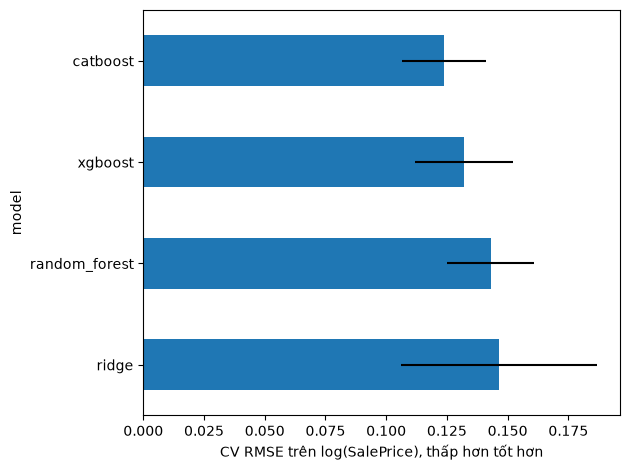

Ứng viên nộp Kaggle: catboost


In [1]:
from pathlib import Path
import sys

project = Path.cwd()
if project.name == "notebooks":
    project = project.parent
sys.path.insert(0, str(project))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.evaluation import DATA, RESULTS, SEED, load_data, make_folds, save_submission
from shutil import copyfile

names = ["ridge", "random_forest", "xgboost", "catboost"]
paths = [RESULTS / "cv" / f"{name}.csv" for name in names]
missing = [path.name for path in paths if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Chạy notebook tương ứng trước: {', '.join(missing)}")
scores = pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)
scores.to_csv(RESULTS / "results_summary.csv", index=False)
best = scores.loc[scores["selected"]].sort_values("cv_mean")
display(best[["model", "variant", "features", "cv_mean", "cv_std"]])
ax = best.plot.barh(x="model", y="cv_mean", xerr="cv_std", legend=False)
ax.invert_yaxis()
ax.set_xlabel("CV RMSE trên log(SalePrice), thấp hơn tốt hơn")
figures = RESULTS / "figures"
figures.mkdir(parents=True, exist_ok=True)
ax.figure.tight_layout()
ax.figure.savefig(figures / "compare_models.png", dpi=160)
plt.show()

folder = RESULTS / "submissions"
winner = best.iloc[0]["model"]
copyfile(folder / f"{winner}.csv", folder / "submission_final.csv")
print(f"Ứng viên nộp Kaggle: {winner}")


## Nhận xét:  
Qua kiểm định chéo 5 fold, CatBoost dùng bộ đặc trưng bổ sung với depth = 5 đạt RMSE trung bình trên thang log thấp nhất (0,12388), tiếp theo là XGBoost (0,13211), Random Forest (0,14303) và Ridge (0,14657). CatBoost cũng có độ lệch chuẩn nhỏ nhất (0,01723), trong khi Ridge có độ lệch chuẩn lớn nhất (0,04034), cho thấy sai số của Ridge dao động nhiều hơn giữa các fold. Dựa trên kết quả CV, nhóm chọn dự đoán của CatBoost làm tệp submission_final.csv để nộp lên Kaggle.